# TellCo user analytics
One month of xDR data from a mobile operator (TellCo). This notebook runs the project package step by step:
**Task 1** overview, **Task 2** engagement, **Task 3** experience, **Task 4** satisfaction, then the MySQL export and model tracking.

How to use: choose the kernel (top right) that has the project installed, then **Run All**. Loading the Excel file takes about a minute.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

from telco_analytics import cleaning, data, db, engagement, experience, overview, satisfaction, viz
from telco_analytics.config import APPS, ENGAGEMENT_METRICS, EXPERIENCE_METRICS, EXPERIENCE_RAW, USAGE_COLS
from telco_analytics.pipeline import raw_session_metric

pd.options.display.float_format = '{:,.2f}'.format
pd.set_option('display.max_columns', 60)
RAW = Path('data/raw/telcom_data.xlsx')
FIG = Path('notebook_figures'); FIG.mkdir(exist_ok=True)


def show(path):
    """Display a saved PNG figure inside the notebook."""
    display(Image(data=Path(path).read_bytes(), format='png'))


import sys
print('Python used by this notebook:', sys.executable)

Python used by this notebook: /usr/bin/python3


## 2. Load the raw data
The loader drops the totals row at the bottom of the sheet and treats `undefined` handsets as missing. The raw file itself is never changed.

In [2]:
raw = data.load_raw(RAW)
print('rows x columns:', raw.shape)
raw.head()

rows x columns: (150000, 54)


,bearer_id,start,start_ms,end,end_ms,duration_ms,imsi,msisdn,imei,last_location,rtt_dl_ms,rtt_ul_ms,tp_dl_kbps,tp_ul_kbps,tcp_dl_retrans_bytes,tcp_ul_retrans_bytes,dl_tp_50_kbps,50_kbps_dl_tp_250_kbps,250_kbps_dl_tp_1_mbps,dl_tp_1_mbps,ul_tp_10_kbps,10_kbps_ul_tp_50_kbps,50_kbps_ul_tp_300_kbps,ul_tp_300_kbps,http_dl_bytes,http_ul_bytes,activity_duration_dl_ms,activity_duration_ul_ms,handset_manufacturer,handset_type,nb_of_sec_with_125000b_vol_dl,nb_of_sec_with_1250b_vol_ul_6250b,nb_of_sec_with_31250b_vol_dl_125000b,nb_of_sec_with_37500b_vol_ul,nb_of_sec_with_6250b_vol_dl_31250b,nb_of_sec_with_6250b_vol_ul_37500b,nb_of_sec_with_vol_dl_6250b,nb_of_sec_with_vol_ul_1250b,social_media_dl,social_media_ul,google_dl,google_ul,email_dl,email_ul,youtube_dl,youtube_ul,netflix_dl,netflix_ul,gaming_dl,gaming_ul,other_dl,other_ul,total_ul,total_dl
0,13114483460844900352,2019-04-04 12:01:18,770.00,2019-04-25 14:35:31,662.00,"1,823,652.00",208201448079117,33664962239,35521209507511,9164566995485190,42.00,5.00,23.00,44.00,NaN,NaN,100.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,NaN,NaN,"37,624.00","38,787.00",Samsung,Samsung Galaxy A5 Sm-A520F,NaN,NaN,NaN,NaN,NaN,NaN,213.00,214.00,"1,545,765.00","24,420.00","1,634,479.00","1,271,433.00","3,563,542.00","137,762.00","15,854,611.00","2,501,332.00","8,198,936.00","9,656,251.00","278,082,303.00","14,344,150.00","171,744,450.00","8,814,393.00","36,749,741.00","308,879,636.00"
1,13114483482878900224,2019-04-09 13:04:04,235.00,2019-04-25 08:15:48,606.00,"1,365,104.00",208201909211140,33681854413,35794009006359,L77566A,65.00,5.00,16.00,26.00,NaN,NaN,100.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,NaN,NaN,168.00,"3,560.00",Samsung,Samsung Galaxy J5 (Sm-J530),NaN,NaN,NaN,NaN,NaN,NaN,971.00,"1,022.00","1,926,113.00","7,165.00","3,493,924.00","920,172.00","629,046.00","308,339.00","20,247,395.00","19,111,729.00","18,338,413.00","17,227,132.00","608,750,074.00","1,170,709.00","526,904,238.00","15,055,145.00","53,800,391.00","653,384,965.00"
2,13114483484080500736,2019-04-09 17:42:11,1.00,2019-04-25 11:58:13,652.00,"1,361,762.00",208200314458056,33760627129,35281510359387,D42335A,NaN,NaN,6.00,9.00,NaN,NaN,100.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,Samsung,Samsung Galaxy A8 (2018),NaN,NaN,NaN,NaN,NaN,NaN,751.00,695.00,"1,684,053.00","42,224.00","8,535,055.00","1,694,064.00","2,690,151.00","672,973.00","19,725,661.00","14,699,576.00","17,587,794.00","6,163,408.00","229,584,621.00","395,630.00","410,692,588.00","4,215,763.00","27,883,638.00","279,807,335.00"
3,13114483485442799616,2019-04-10 00:31:25,486.00,2019-04-25 07:36:35,171.00,"1,321,509.00",208201402342131,33750343200,35356610164913,T21824A,NaN,NaN,44.00,44.00,NaN,NaN,100.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,NaN,NaN,"3,330.00","37,882.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.00,207.00,"644,121.00","13,372.00","9,023,734.00","2,788,027.00","1,439,754.00","631,229.00","21,388,122.00","15,146,643.00","13,994,646.00","1,097,942.00","799,538,153.00","10,849,722.00","749,039,933.00","12,797,283.00","43,324,218.00","846,028,530.00"
4,13114483499480700928,2019-04-12 20:10:23,565.00,2019-04-25 10:40:32,954.00,"1,089,009.00",208201401415120,33699795932,35407009745539,D88865A,NaN,NaN,6.00,9.00,NaN,NaN,100.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,NaN,NaN,0.00,0.00,Samsung,Samsung Sm-G390F,NaN,NaN,NaN,NaN,NaN,NaN,607.00,604.00,"862,600.00","50,188.00","6,248,284.00","1,500,559.00","1,936,496.00","173,853.00","15,259,380.00","18,962,873.00","17,124,581.00","415,218.00","527,707,248.00","3,529,801.00","550,709,500.00","13,910,322.00","38,542,814.00","569,138,589.00"


## 3. Data dictionary

In [3]:
fd_path = Path('data/raw/Field_Descriptions.xlsx')
fields = pd.read_excel(fd_path) if fd_path.exists() else None
print(f'{len(fields)} documented fields') if fields is not None else print('Field_Descriptions.xlsx not found in data/raw')
fields.head(10) if fields is not None else None

56 documented fields


,Fields,Description
0,bearer id,xDr session identifier
1,Dur. (ms),Total Duration of the xDR (in ms)
2,Start,Start time of the xDR (first frame timestamp)
3,Start ms,Milliseconds offset of start time for the xDR ...
4,End,End time of the xDR (last frame timestamp)
5,End ms,Milliseconds offset of end time of the xDR (la...
6,Dur. (s),Total Duration of the xDR (in s)
7,IMSI,International Mobile Subscriber Identity
8,MSISDN/Number,MS International PSTN/ISDN Number of mobile - ...
9,IMEI,International Mobile Equipment Identity


In [4]:
overview.variable_summary(raw)

,variable,dtype,non_null,pct_missing,n_unique
0,bearer_id,object,150000,0.00,134709
1,start,datetime64[us],150000,0.00,111881
2,start_ms,float64,150000,0.00,1000
3,end,datetime64[us],150000,0.00,100962
4,end_ms,float64,150000,0.00,1000
5,duration_ms,float64,150000,0.00,89525
6,imsi,Int64,149431,0.38,107265
7,msisdn,Int64,148935,0.71,106856
8,imei,Int64,149429,0.38,107270
9,last_location,object,148848,0.77,45547


> The dictionary lists `Dur. (s)`, but the file has `Dur. (ms)` and a second column `Dur. (ms).1` that is exactly 1,000 times larger. The loader keeps `Dur. (ms)` and drops the duplicate.

# Task 1 - User overview
## 4. Top handsets and manufacturers

,handset_type,sessions
0,Huawei B528S-23A,19752
1,Apple iPhone 6S (A1688),9419
2,Apple iPhone 6 (A1586),9023
3,Apple iPhone 7 (A1778),6326
4,Apple iPhone Se (A1723),5187
5,Apple iPhone 8 (A1905),4993
6,Apple iPhone Xr (A2105),4568
7,Samsung Galaxy S8 (Sm-G950F),4520
8,Apple iPhone X (A1901),3813
9,Samsung Galaxy A5 Sm-A520F,3724


,handset_manufacturer,sessions
0,Apple,59565
1,Samsung,40839
2,Huawei,34423


,handset_manufacturer,handset_type,sessions
0,Apple,Apple iPhone 6S (A1688),9419
1,Apple,Apple iPhone 6 (A1586),9023
2,Apple,Apple iPhone 7 (A1778),6326
3,Apple,Apple iPhone Se (A1723),5187
4,Apple,Apple iPhone 8 (A1905),4993
5,Samsung,Samsung Galaxy S8 (Sm-G950F),4520
6,Samsung,Samsung Galaxy A5 Sm-A520F,3724
7,Samsung,Samsung Galaxy J5 (Sm-J530),3696
8,Samsung,Samsung Galaxy J3 (Sm-J330),3484
9,Samsung,Samsung Galaxy S7 (Sm-G930X),3199


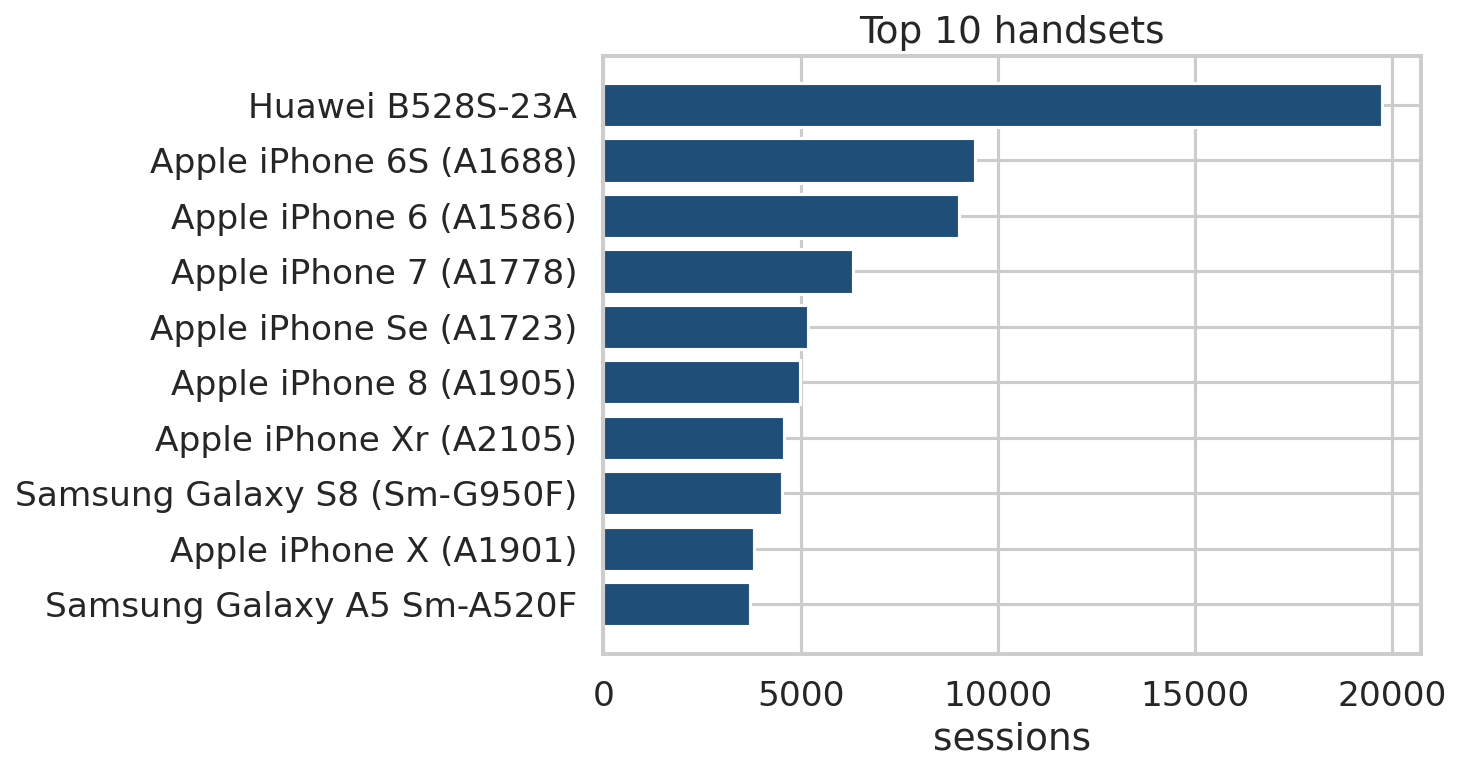

In [5]:
top_h = overview.top_handsets(raw, 10)
display(top_h)
display(overview.top_manufacturers(raw, 3))
display(overview.top_handsets_per_manufacturer(raw, 3, 5))
show(viz.barh(top_h, 'handset_type', 'sessions', 'Top 10 handsets', FIG / 'handsets.png'))

**Interpretation for marketing.** Apple, Samsung and Huawei are the top three manufacturers. The single most common device is a Huawei B528S-23A, which is a home router rather than a phone, so there is a separate broadband segment next to the handset users.
**Recommendation:** run data-plan and upgrade offers for the popular iPhones and Samsung models, and design a separate fixed-wireless bundle for router users.

## 5. Missing values and outliers
Missing values and values outside 1.5 x IQR are replaced with the mean of the normal values, as the brief specifies.

In [6]:
usage_clean, usage_report = cleaning.treat_numeric(raw, USAGE_COLS)
usage_report.round(2)

,column,pct_missing,pct_outlier,replacement_mean
0,duration_ms,0.00,4.79,"92,261.14"
1,total_dl,0.00,0.00,"454,643,430.08"
2,total_ul,0.00,0.16,"41,119,711.31"
3,social_media_dl,0.00,0.00,"1,795,321.77"
4,google_dl,0.00,0.00,"5,750,752.62"
5,email_dl,0.00,0.00,"1,791,728.87"
6,youtube_dl,0.00,0.00,"11,634,072.50"
7,netflix_dl,0.00,0.00,"11,626,851.72"
8,gaming_dl,0.00,0.00,"422,044,702.60"
9,other_dl,0.00,0.00,"421,100,544.19"


## 6. Per-user aggregation (Task 1.1)

In [7]:
users = overview.aggregate_user_behaviour(usage_clean)
print('users:', len(users))
users.head()

users: 106856


,msisdn,n_sessions,duration_ms,total_dl,total_ul,social_media_bytes,google_bytes,email_bytes,youtube_bytes,netflix_bytes,gaming_bytes,other_bytes,total_bytes
0,33601001722,1,"116,720.00","842,637,466.00","36,053,108.00","2,232,135.00","4,389,005.00","1,331,362.00","21,624,548.00","27,180,981.00","812,458,661.00","386,570,872.00","878,690,574.00"
1,33601001754,1,"181,230.00","120,755,184.00","36,104,459.00","2,660,565.00","5,334,863.00","3,307,781.00","12,432,223.00","11,221,763.00","119,750,078.00","281,710,071.00","156,859,643.00"
2,33601002511,1,"134,969.00","556,659,663.00","39,306,820.00","3,195,623.00","3,443,126.00","3,205,380.00","21,333,570.00","19,353,900.00","538,827,713.00","501,693,672.00","595,966,483.00"
3,33601007832,1,"49,878.00","401,993,172.00","20,327,526.00","280,294.00","9,678,493.00","2,284,670.00","6,977,321.00","1,942,092.00","391,126,127.00","35,279,702.00","422,320,698.00"
4,33601008617,2,"37,104.00","1,363,130,417.00","94,280,527.00","2,912,542.00","18,499,616.00","3,305,469.00","41,533,002.00","49,201,724.00","1,314,797,820.00","804,804,484.00","1,457,410,944.00"


## 7. Basic metrics and dispersion
Mean and median show the typical customer; the gap between them and the skew show how concentrated usage is.

In [8]:
cols = ['n_sessions', 'duration_ms', 'total_dl', 'total_ul', 'total_bytes'] + [f'{a}_bytes' for a in APPS]
overview.dispersion(users, cols)

,variable,mean,median,std,variance,min,max,range,iqr,cv,skew,kurtosis
0,n_sessions,1.39,1.00,0.81,0.65,1.00,18.00,17.00,1.00,0.58,3.35,20.74
1,duration_ms,"128,910.29","97,154.00","102,097.57","10,423,913,469.74","7,142.00","1,964,099.37","1,956,957.37","98,316.00",0.79,2.70,16.15
2,total_dl,"633,652,680.89","570,367,723.00","464,555,056.46","215,811,400,483,495,456.00","8,827,082.00","8,156,743,493.00","8,147,916,411.00","492,537,426.50",0.73,2.15,10.68
3,total_ul,"57,307,011.37","46,775,508.50","35,615,851.71","1,268,488,892,846,278.25","9,512,288.00","729,577,380.00","720,065,092.00","29,236,553.50",0.62,2.90,16.69
4,total_bytes,"690,959,692.26","617,922,683.50","491,048,680.03","241,128,806,157,362,752.00","33,249,009.00","8,846,226,494.00","8,812,977,485.00","498,835,677.75",0.71,2.27,11.62
5,social_media_bytes,"2,547,966.82","2,303,756.00","1,908,038.04","3,640,609,170,313.23","1,563.00","43,374,779.00","43,373,216.00","2,096,227.50",0.75,2.09,11.52
6,google_bytes,"10,882,434.42","9,586,153.00","7,544,861.44","56,924,934,100,955.22","40,330.00","152,191,852.00","152,151,522.00","7,272,103.75",0.69,2.40,12.62
7,email_bytes,"3,148,795.81","2,799,824.50","2,222,400.10","4,939,062,202,615.18","18,176.00","42,418,782.00","42,400,606.00","2,172,716.50",0.71,2.37,12.60
8,youtube_bytes,"31,558,399.28","26,800,376.00","21,294,917.68","453,473,519,074,732.88","78,903.00","452,958,769.00","452,879,866.00","19,296,887.25",0.67,2.54,13.97
9,netflix_bytes,"31,538,332.31","26,718,889.50","21,289,556.97","453,245,235,971,980.56","184,569.00","399,519,079.00","399,334,510.00","19,420,984.25",0.68,2.48,12.69


**Interpretation.** Every variable is right-skewed (skewness above 2): most users are light, and a few heavy users pull the averages up. That is why the later steps segment users instead of relying on the mean.

## 8. Graphical univariate analysis

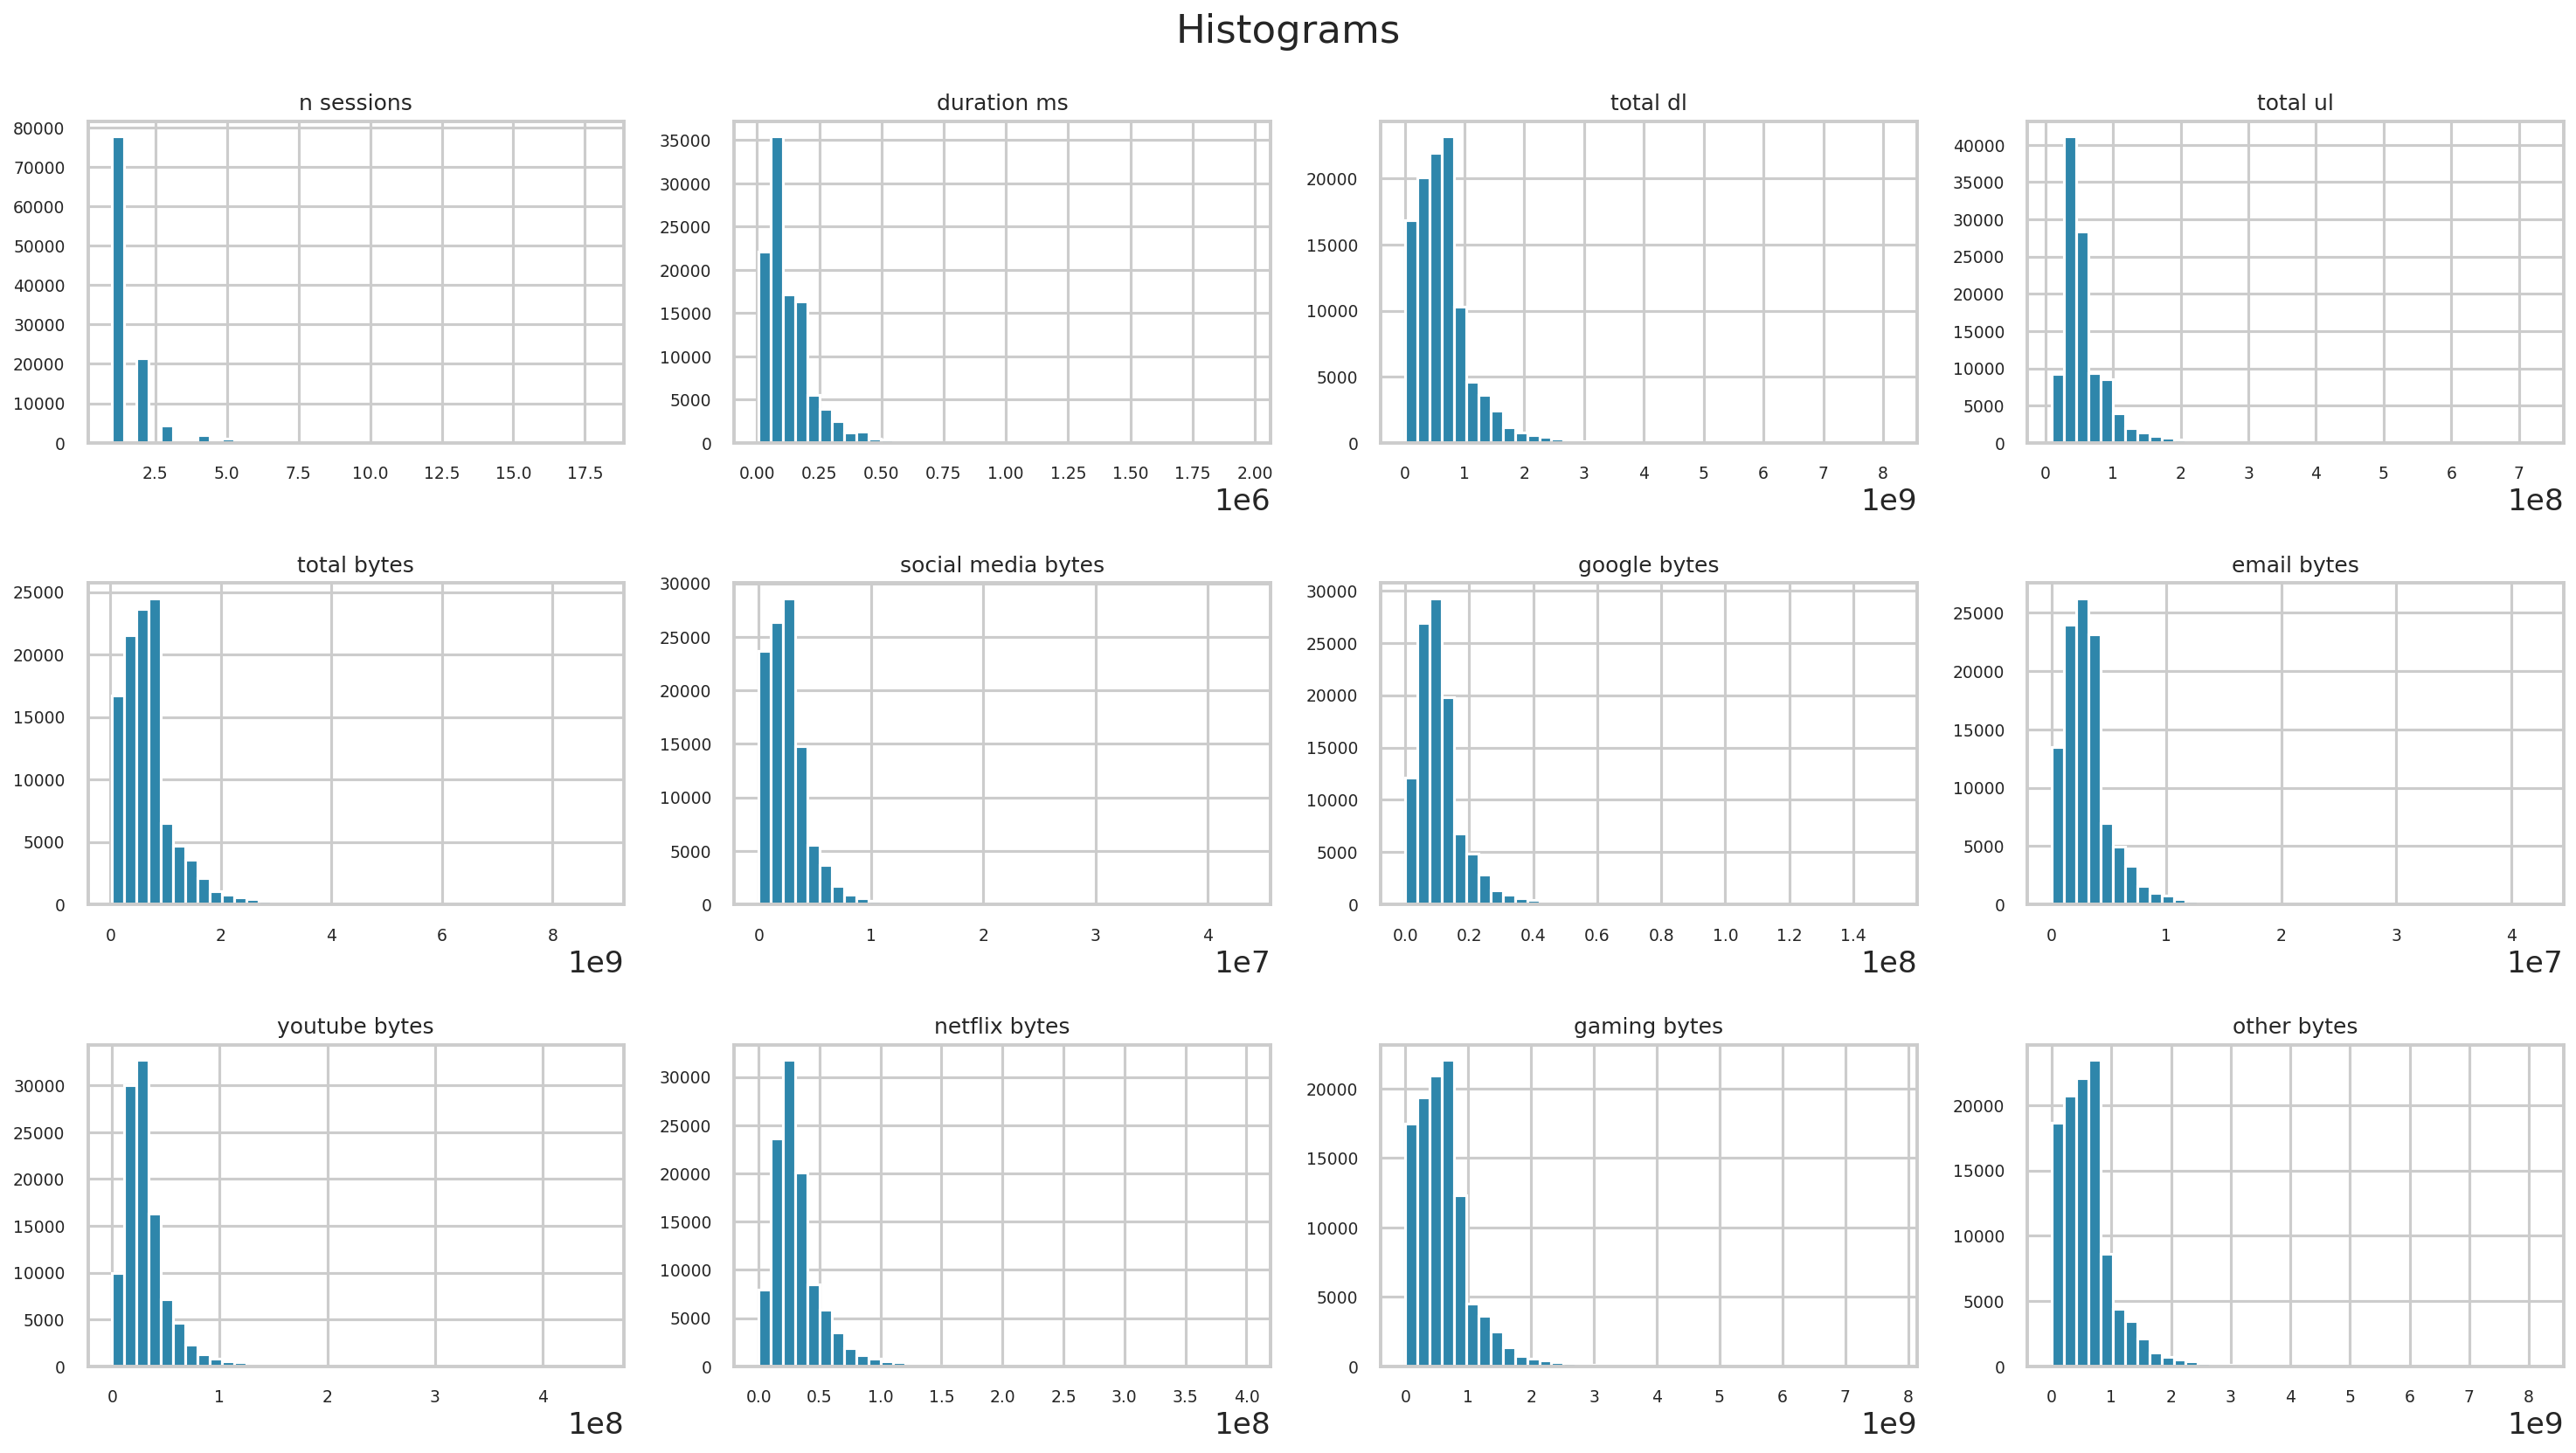

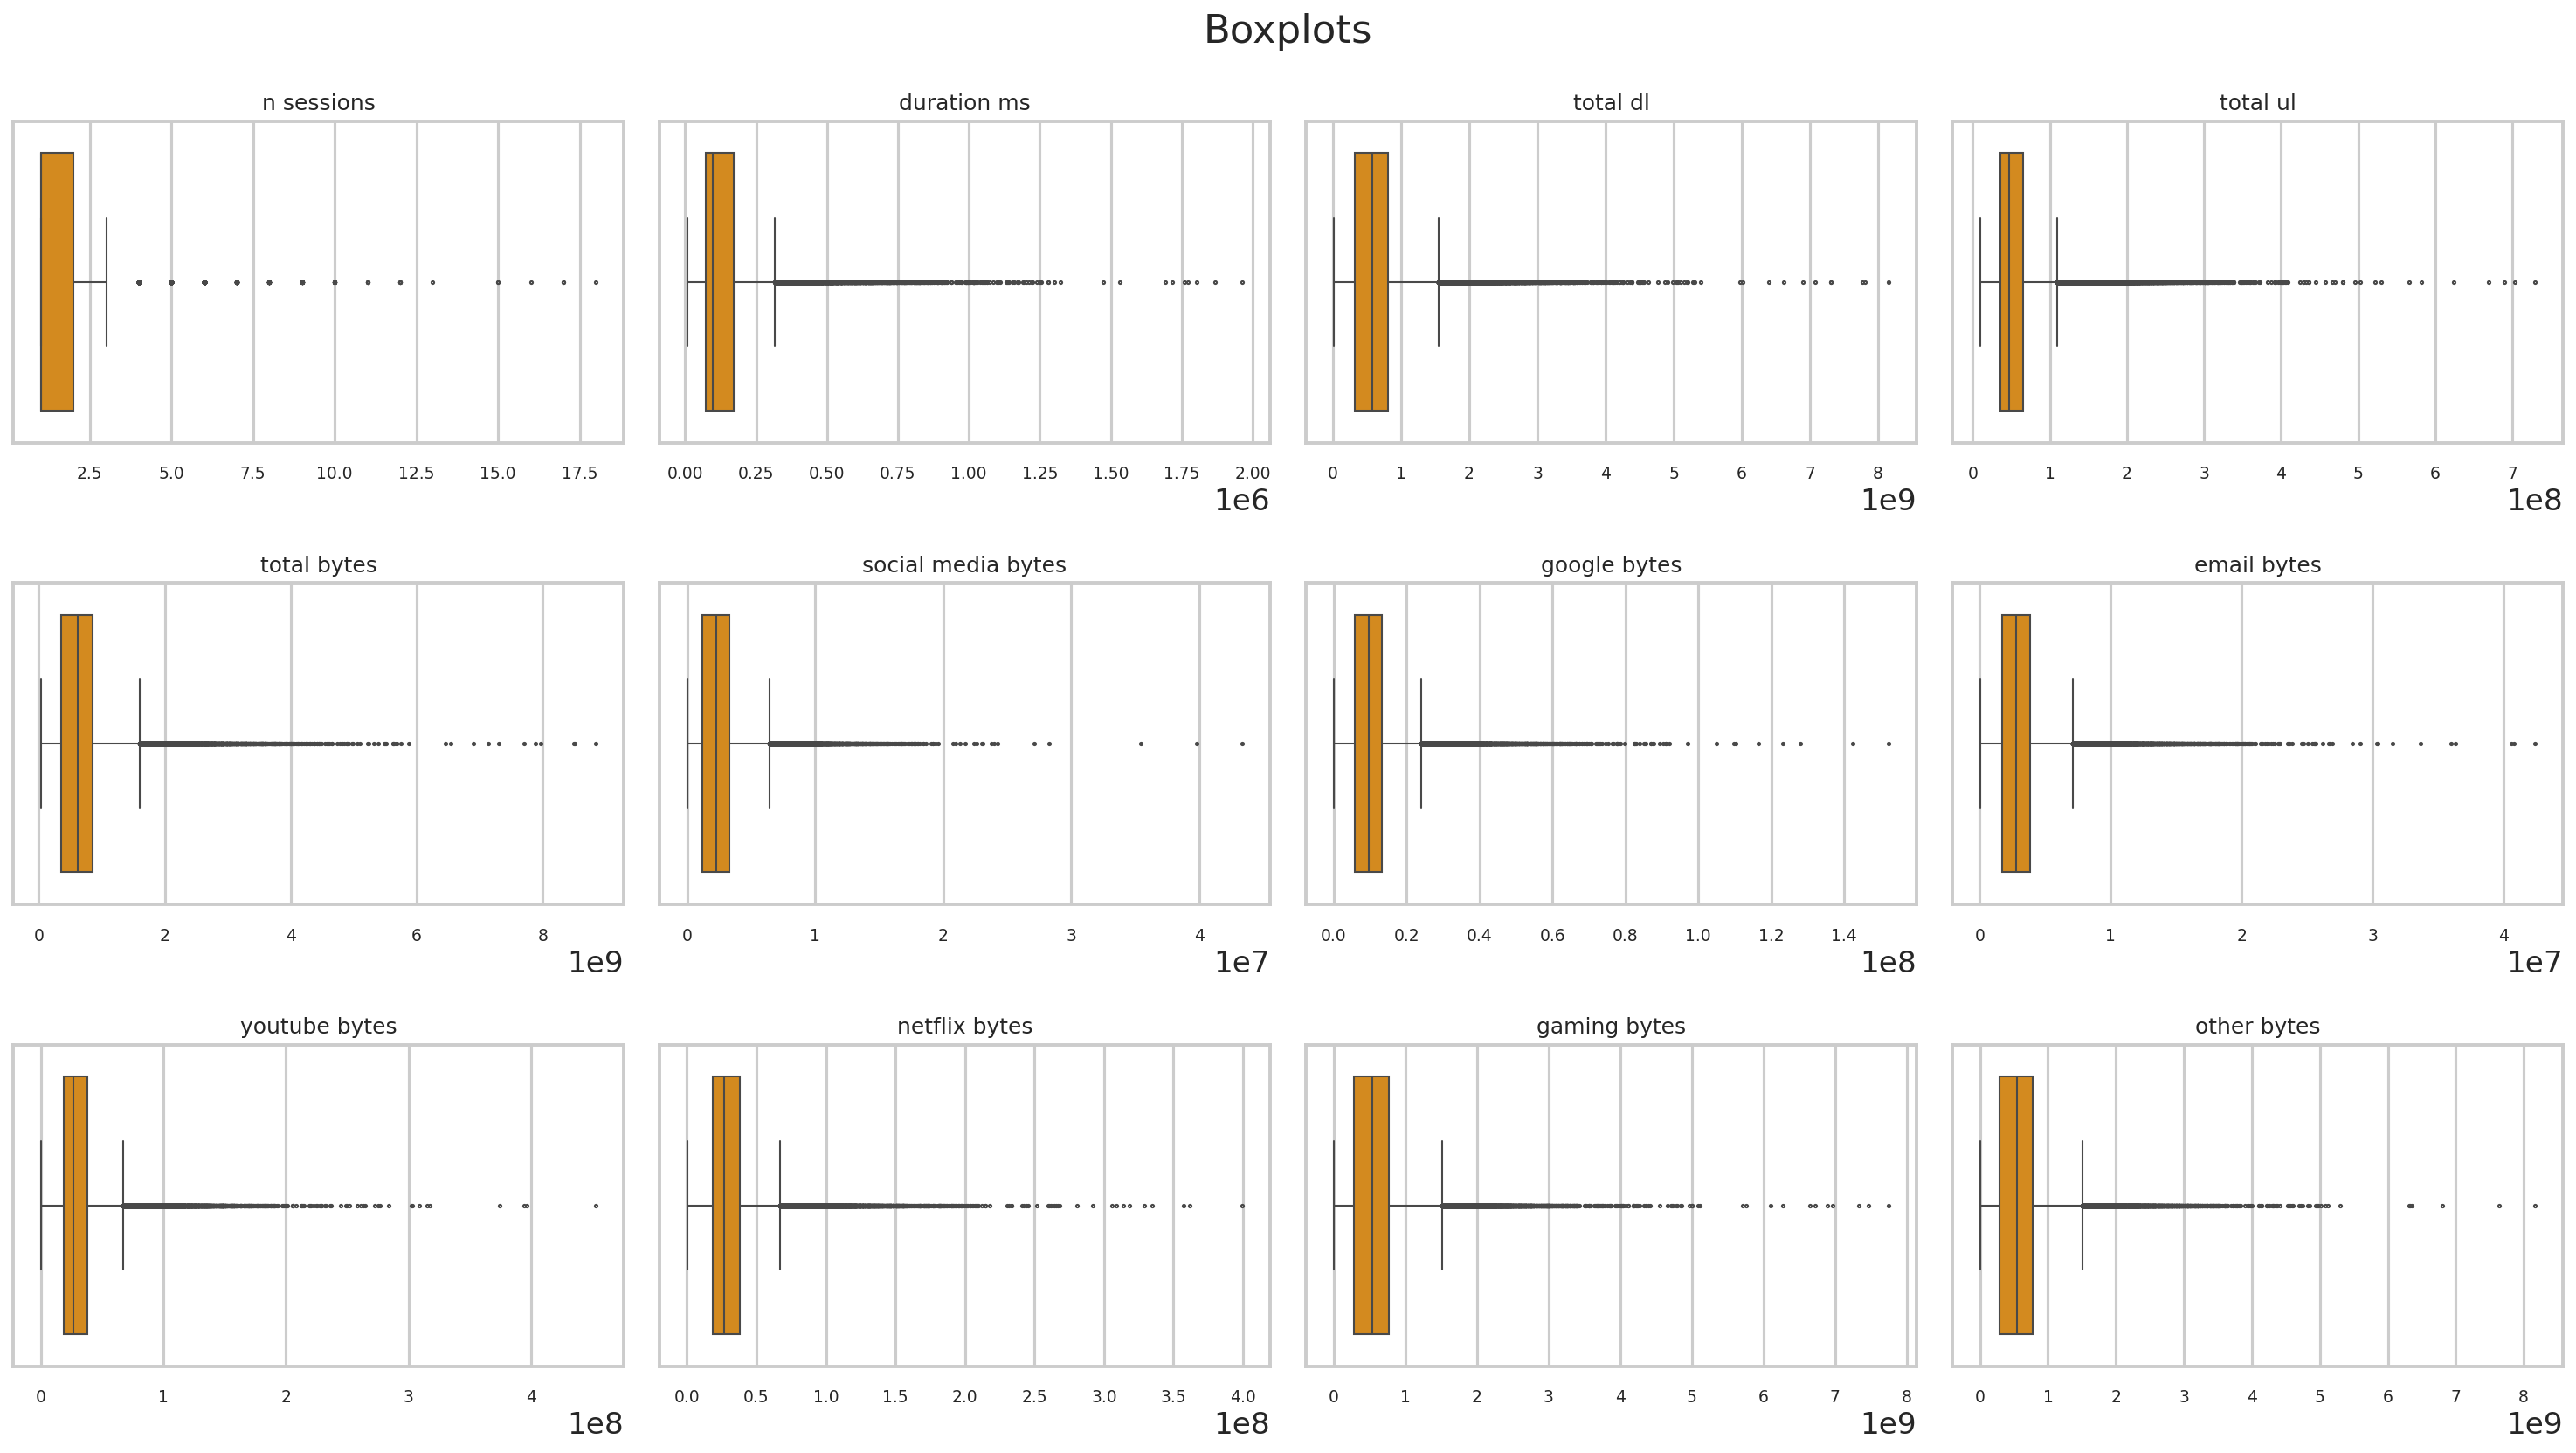

In [9]:
show(viz.hist_grid(users, cols, 'Histograms', FIG / 'hist.png'))
show(viz.box_grid(users, cols, 'Boxplots', FIG / 'box.png'))

## 9. Bivariate analysis: each application against total data

,application,pearson_r_with_total
0,gaming,1.00
1,youtube,0.71
2,netflix,0.70
3,google,0.68
4,email,0.66
5,social_media,0.62
6,other,0.62


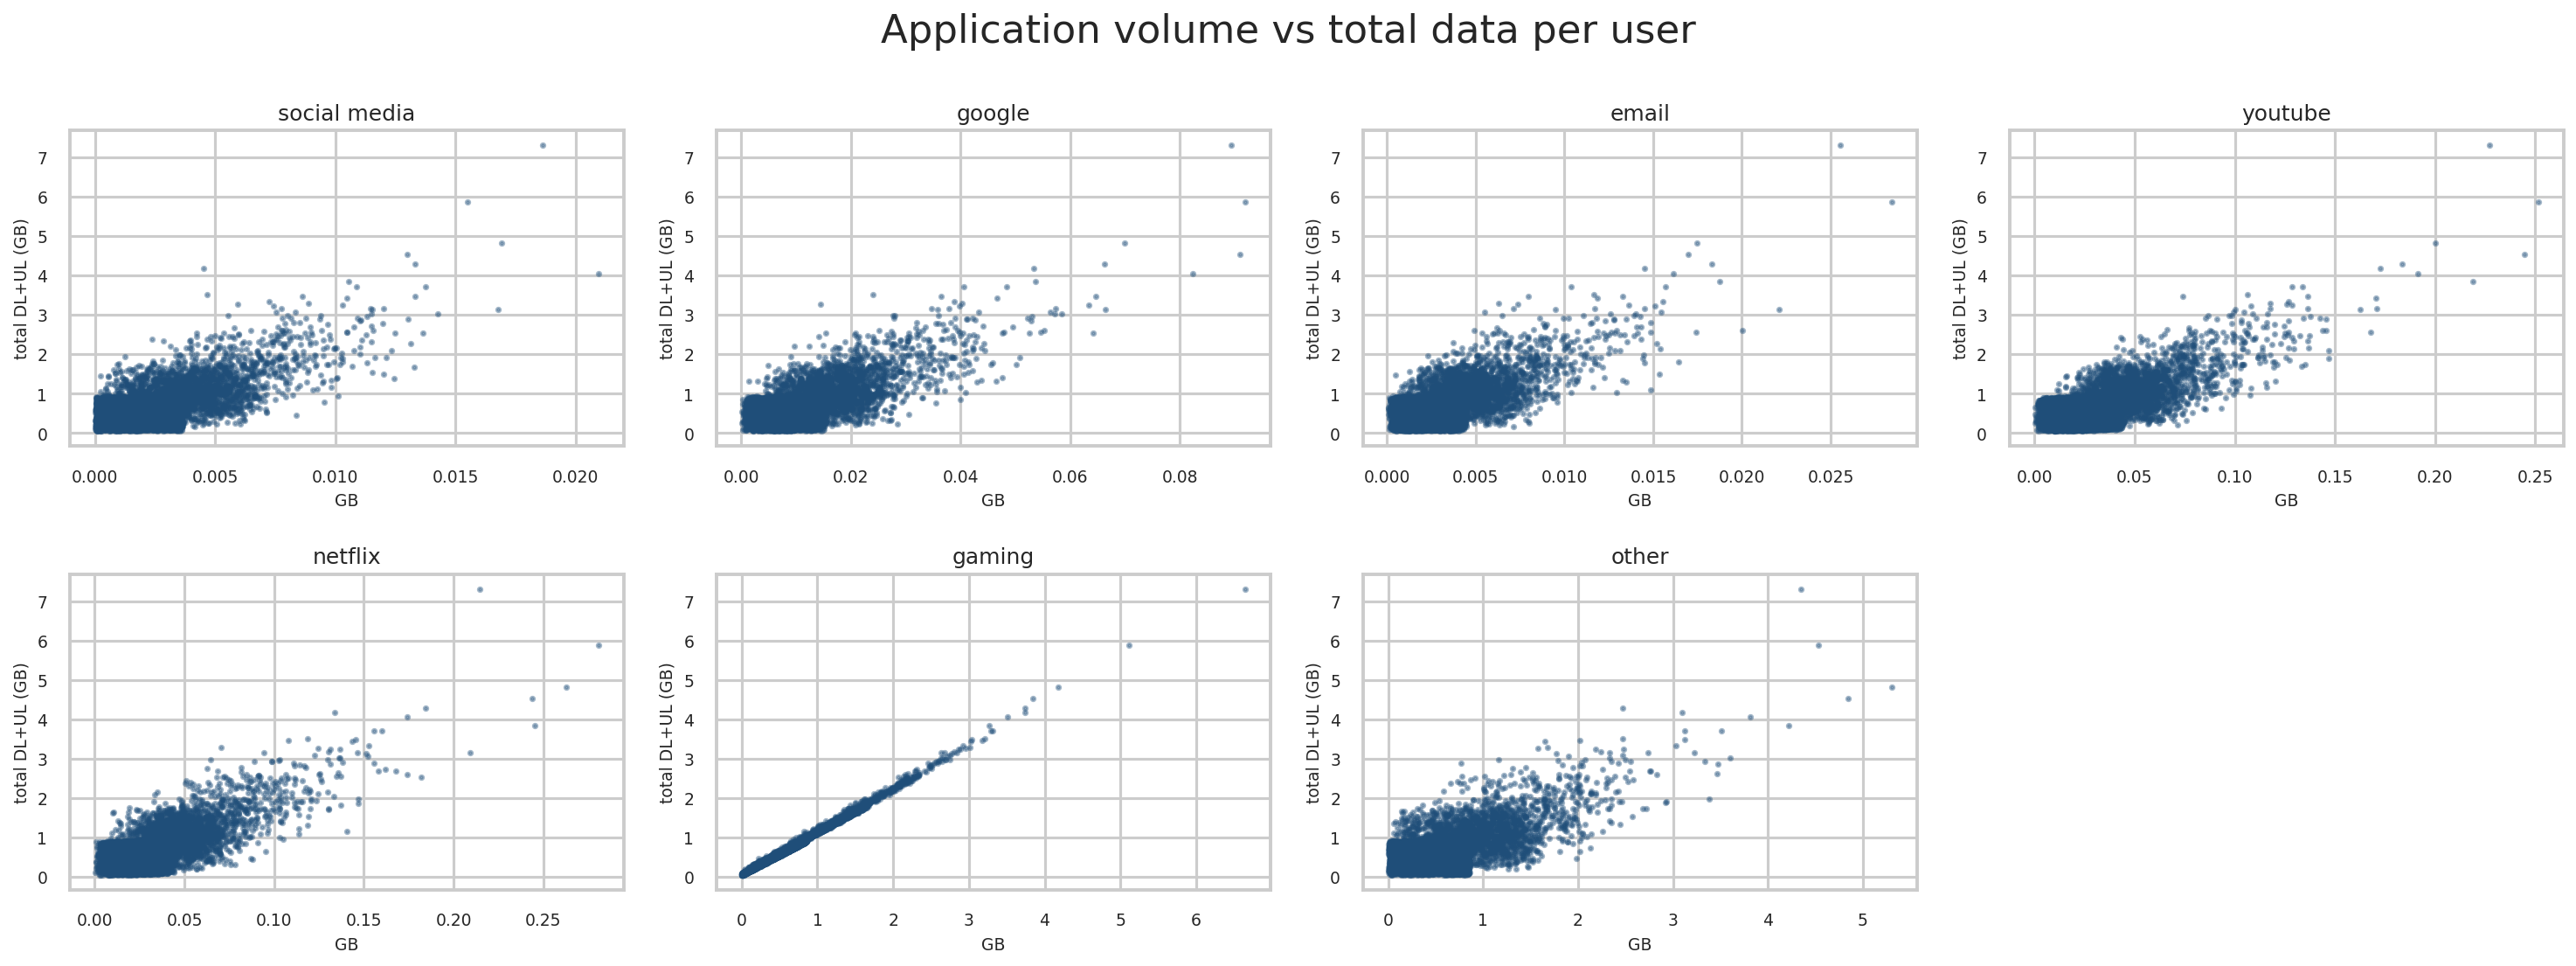

In [10]:
display(overview.app_vs_total(users))
show(viz.scatter_vs_total(users, [f'{a}_bytes' for a in APPS], 'total_bytes', FIG / 'bivariate.png'))

**Interpretation.** All applications correlate positively with total data. Gaming is almost perfectly correlated (about 1.0) because the application columns in this extract do not add up to the session total (they exceed it in every session), so the application mix should not be over-interpreted.

## 10. Decile classes by total duration
Users are split into 10 duration deciles; the top five (6-10) are shown.

In [11]:
deciles = overview.duration_deciles(users)
deciles['share_of_all_data'] = deciles['total_bytes'] / users['total_bytes'].sum()
display(deciles)
print('Top five deciles hold', f"{deciles['share_of_all_data'].sum():.0%}", 'of all traffic')

,decile,users,total_duration_ms,total_bytes,share_of_all_data
0,6,10686,"1,168,426,457.05","6,399,377,492,243.08",0.09
1,7,10685,"1,485,255,206.83","6,114,194,683,663.22",0.08
2,8,10686,"1,793,054,844.35","7,408,424,005,276.08",0.10
3,9,10685,"2,197,695,160.43","8,635,761,334,756.46",0.12
4,10,10686,"3,830,981,180.17","16,221,370,980,322.10",0.22


Top five deciles hold 61% of all traffic


**Interpretation.** The five longest-duration deciles carry about 61% of all traffic, and the top decile alone about 22%.

## 11. Correlation matrix

,social_media_bytes,google_bytes,email_bytes,youtube_bytes,netflix_bytes,gaming_bytes,other_bytes
social_media_bytes,1.00,0.64,0.63,0.66,0.66,0.59,0.59
google_bytes,0.64,1.00,0.69,0.72,0.72,0.64,0.64
email_bytes,0.63,0.69,1.00,0.70,0.71,0.63,0.63
youtube_bytes,0.66,0.72,0.70,1.00,0.74,0.66,0.66
netflix_bytes,0.66,0.72,0.71,0.74,1.00,0.66,0.66
gaming_bytes,0.59,0.64,0.63,0.66,0.66,1.00,0.59
other_bytes,0.59,0.64,0.63,0.66,0.66,0.59,1.00


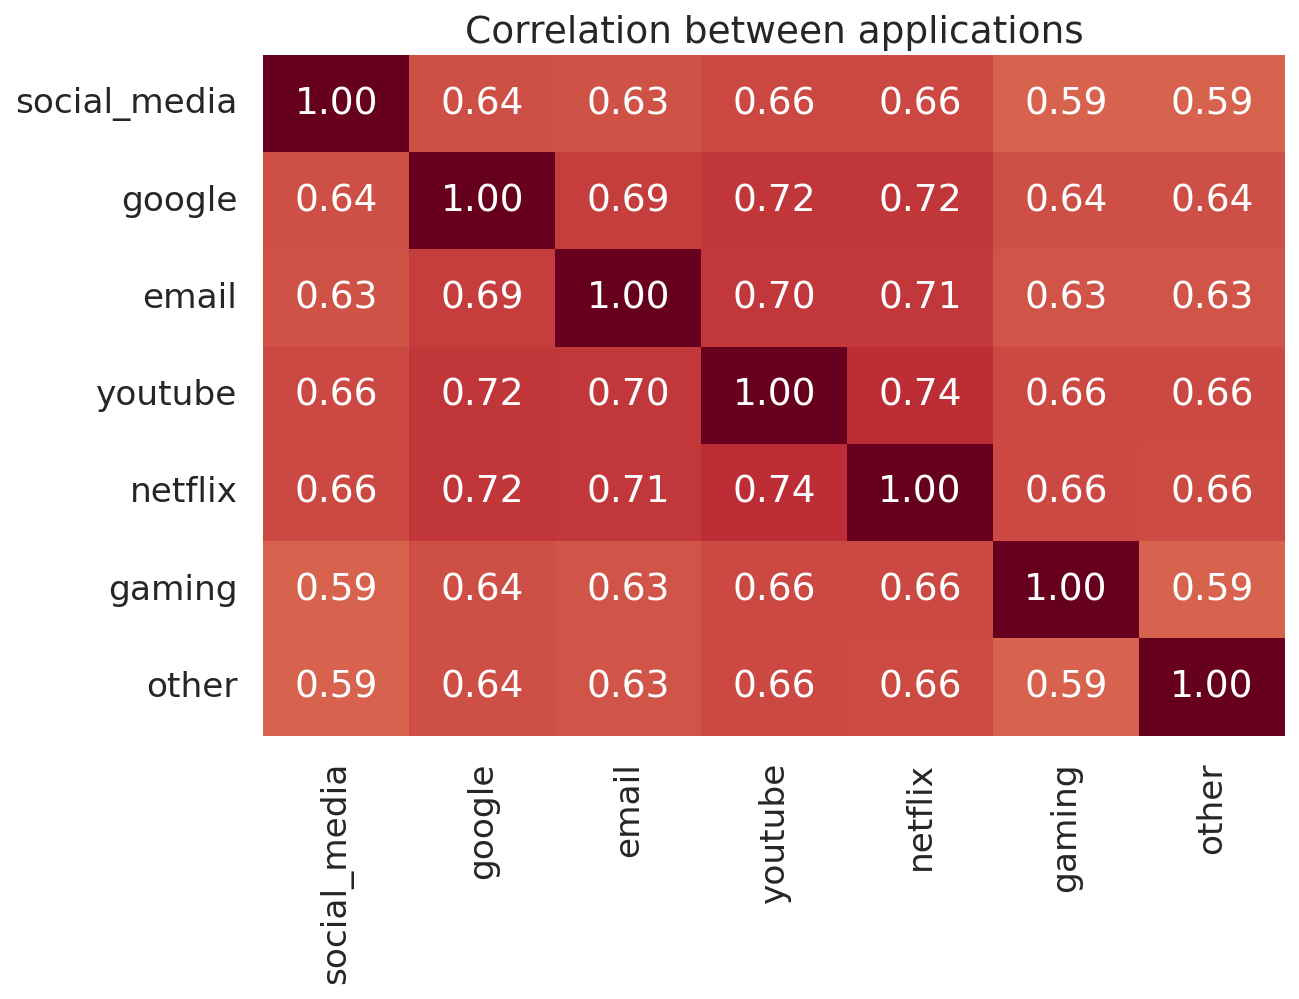

In [12]:
corr = overview.app_correlation(users)
display(corr.round(2))
show(viz.heatmap(corr.rename(index=lambda c: c.replace('_bytes',''), columns=lambda c: c.replace('_bytes','')),
                          'Correlation between applications', FIG / 'corr.png'))

**Interpretation.** All correlations are positive, between about 0.59 and 0.74. The strongest pair is YouTube and Netflix. Heavy users tend to be heavy on every application.

## 12. Principal component analysis

,component,explained_variance_ratio,cumulative
0,PC1,0.71,0.71
1,PC2,0.06,0.77
2,PC3,0.06,0.82
3,PC4,0.05,0.88
4,PC5,0.04,0.92
5,PC6,0.04,0.96
6,PC7,0.04,1.00


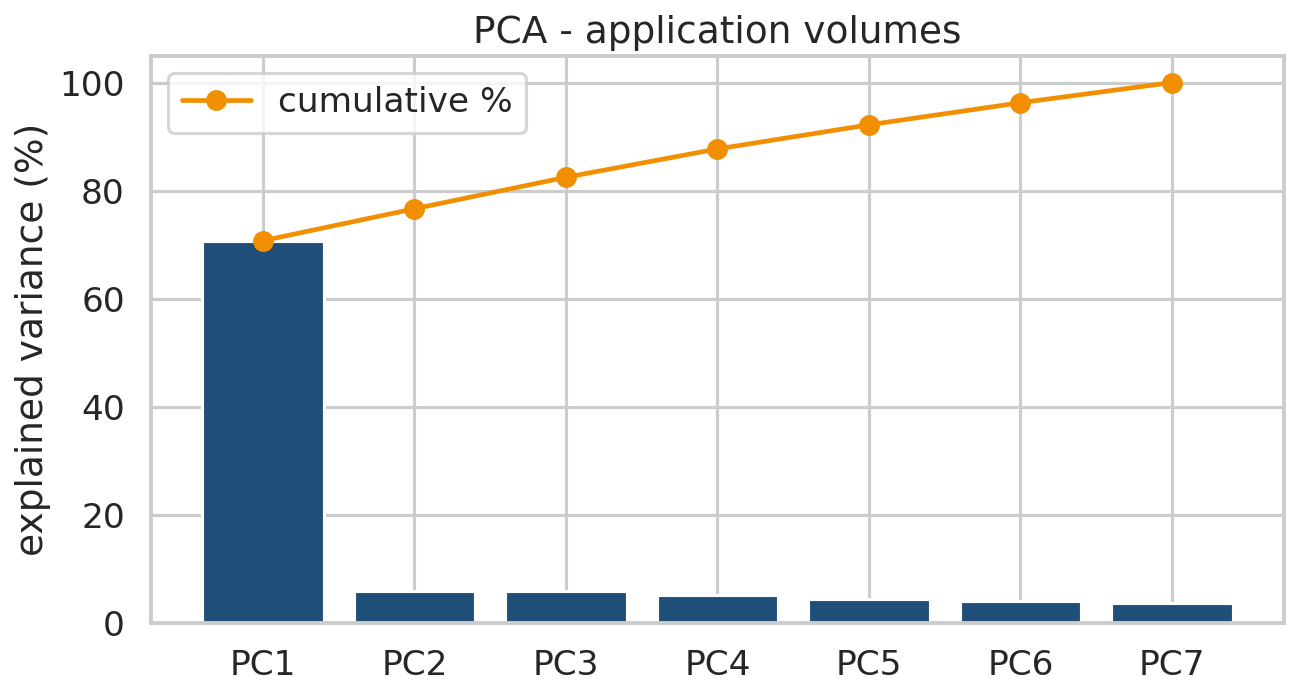

In [13]:
pca_var, loadings = overview.pca_summary(users)
display(pca_var)
show(viz.scree(pca_var, FIG / 'scree.png'))

**PCA interpretation**
- The first component explains about 71% of the variance and is essentially overall data volume.
- Each of the other six components explains only about 4-6%.
- Two components cover about 77% and five cover about 92%.
- Users differ mostly in how much they use, not in which applications they use.

# Task 2 - User engagement
## 13. Engagement metrics and top 10 customers

In [14]:
eng = engagement.engagement_metrics(usage_clean)
for metric, table in engagement.top_n_per_metric(eng, 10).items():
    print('Top 10 by', metric); display(table)

Top 10 by sessions_frequency


,msisdn,sessions_frequency
0,33626320676,18
1,33614892860,17
2,33625779332,17
3,33659725664,16
4,33675877202,15
5,33760536639,15
6,33667163239,13
7,33603127838,12
8,33604515716,12
9,33627080969,12


Top 10 by duration_ms


,msisdn,duration_ms
0,33659725664,"1,964,099.37"
1,33626320676,"1,867,488.91"
2,33675877202,"1,803,752.37"
3,33659359429,"1,771,442.55"
4,33614892860,"1,760,466.91"
5,33760536639,"1,715,567.50"
6,33625779332,"1,692,846.19"
7,33664712899,"1,533,638.96"
8,33786323068,"1,474,704.09"
9,33606582008,"1,322,251.00"


Top 10 by total_traffic_bytes


,msisdn,total_traffic_bytes
0,33614892860,"8,846,226,494.00"
1,33760536639,"8,514,773,963.00"
2,33625779332,"8,499,620,722.00"
3,33626320676,"7,971,167,261.00"
4,33675877202,"7,891,110,608.00"
5,33659725664,"7,705,862,783.00"
6,33666464084,"7,308,500,938.00"
7,33760413819,"7,132,370,514.00"
8,33664712899,"6,903,962,803.31"
9,33698792269,"6,540,899,126.00"


## 14. K-means (k=3) on normalised metrics

least engaged cluster: 1


,0,1,2
cluster,0.00,1.00,2.00
users,"21,753.00","80,760.00","4,343.00"
sessions_frequency_min,1.00,1.00,3.00
sessions_frequency_max,4.00,2.00,18.00
sessions_frequency_mean,2.15,1.04,4.19
sessions_frequency_sum,"46,663.00","84,085.00","18,187.00"
duration_ms_min,"18,235.00","7,142.00","85,554.00"
duration_ms_max,"514,316.00","261,421.00","1,964,099.37"
duration_ms_mean,"197,622.83","93,606.06","441,244.14"
duration_ms_sum,"4,298,889,426.87","7,559,625,728.76","1,916,323,299.98"


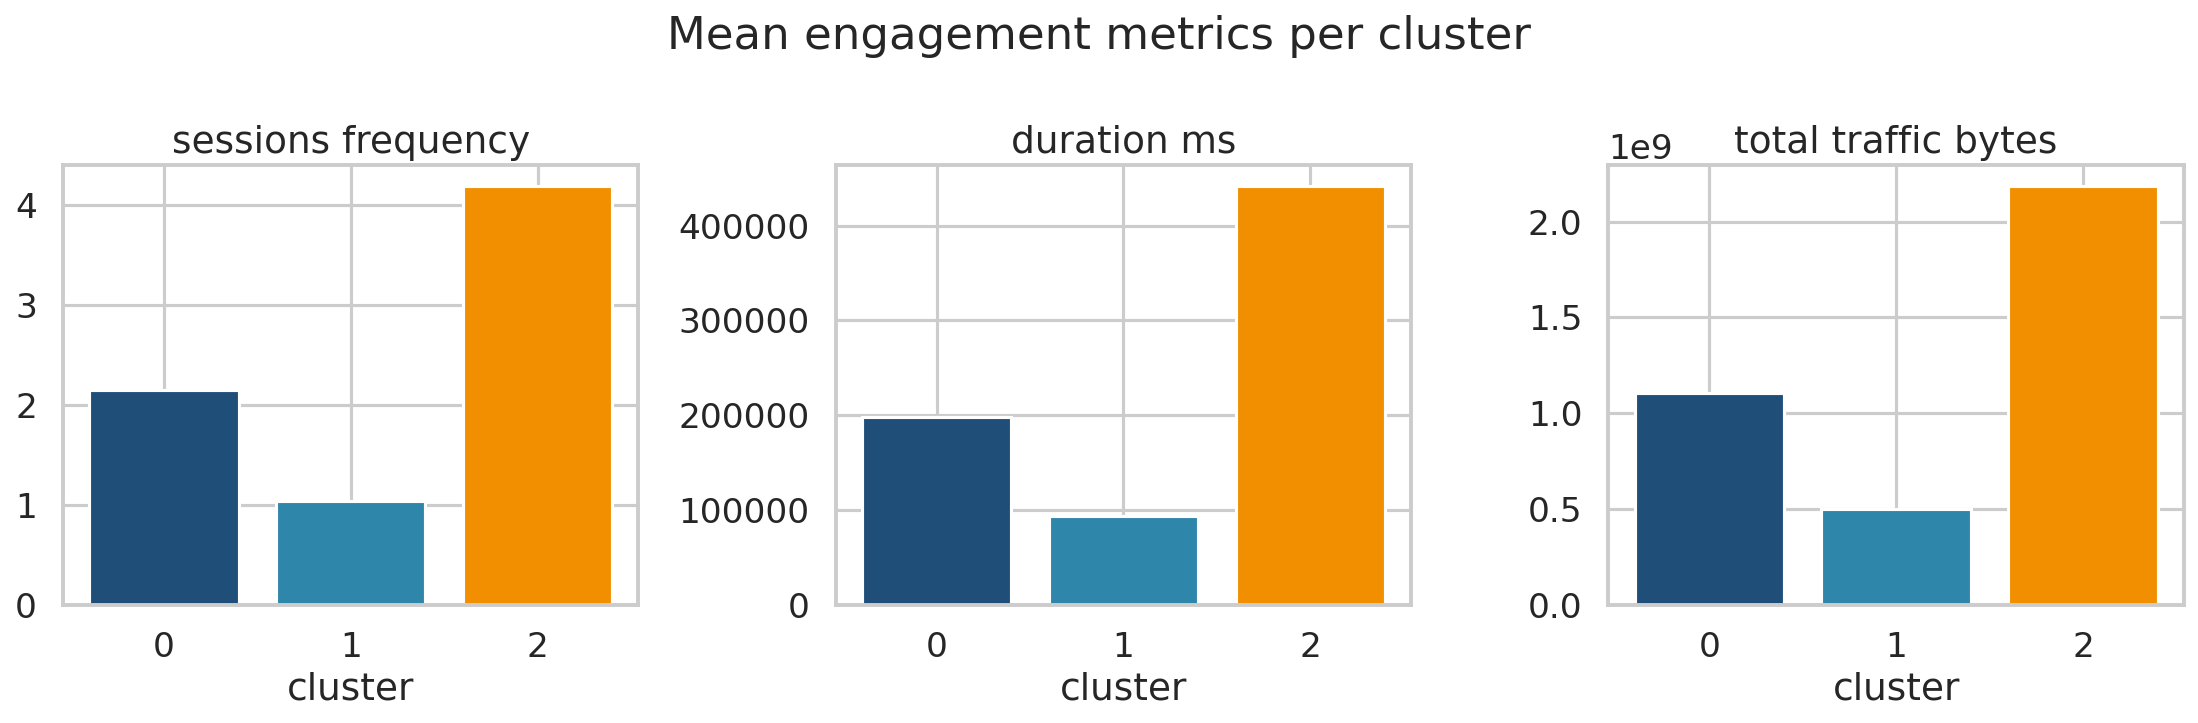

In [15]:
labels, eng_model, eng_scaler, eng_scaled = engagement.cluster_engagement(eng, 3)
least = engagement.least_engaged_cluster(eng_model)
e_stats = engagement.cluster_stats(eng, labels)
e_stats['users_pct'] = 100 * e_stats['users'] / e_stats['users'].sum()
print('least engaged cluster:', least)
display(e_stats.T)
show(viz.cluster_bars(e_stats, ENGAGEMENT_METRICS, 'Mean engagement metrics per cluster', FIG / 'eng_clusters.png'))

**Interpretation.** About three quarters of users are in the least engaged cluster (about one session, short duration). A small cluster of about 4% of users has about four sessions, the longest duration and the most data per user.

## 15. Most engaged users per application and the top 3 applications

Top 10 users: social_media


,msisdn,social_media_bytes
0,33626320676,"43,374,779.00"
1,33760536639,"39,783,189.00"
2,33659725664,"35,412,358.00"
3,33614892860,"28,294,544.00"
4,33625779332,"27,135,500.00"
5,33667163239,"24,247,850.00"
6,33786323068,"23,974,919.00"
7,33669068942,"23,800,834.00"
8,33603127838,"23,077,825.00"
9,33658490784,"23,000,066.00"


Top 10 users: google


,msisdn,google_bytes
0,33626320676,"152,191,852.00"
1,33625779332,"142,307,915.00"
2,33614892860,"127,973,787.00"
3,33760536639,"123,223,099.00"
4,33659725664,"116,516,345.00"
5,33786323068,"110,254,484.00"
6,33675877202,"109,860,502.00"
7,33667163239,"105,032,696.00"
8,33761268199,"97,089,988.00"
9,33698756430,"91,935,151.00"


Top 10 users: email


...

Top 10 users: gaming


,msisdn,gaming_bytes
0,33614892860,"7,749,432,234.00"
1,33760536639,"7,461,045,228.00"
2,33625779332,"7,326,673,487.00"
3,33675877202,"6,970,567,597.00"
4,33626320676,"6,887,572,116.00"
5,33659725664,"6,725,559,211.00"
6,33666464084,"6,646,303,338.00"
7,33760413819,"6,268,619,592.00"
8,33664712899,"6,103,856,008.00"
9,33698792269,"5,753,743,069.00"


Top 10 users: other


,msisdn,other_bytes
0,33626320676,"8,167,877,776.00"
1,33614892860,"7,639,263,572.00"
2,33675877202,"6,798,515,150.00"
3,33625779332,"6,354,583,086.00"
4,33603127838,"6,326,670,874.00"
5,33659725664,"6,317,415,487.00"
6,33626948251,"5,305,447,882.00"
7,33627080969,"5,117,790,890.00"
8,33761268199,"5,077,779,438.00"
9,33658361927,"5,013,650,844.00"


,application,total_bytes,share_of_app_volume_pct
0,gaming,"64,088,917,409,212.00",46.93
1,other,"63,954,252,515,822.00",46.83
2,youtube,"3,372,204,313,367.00",2.47


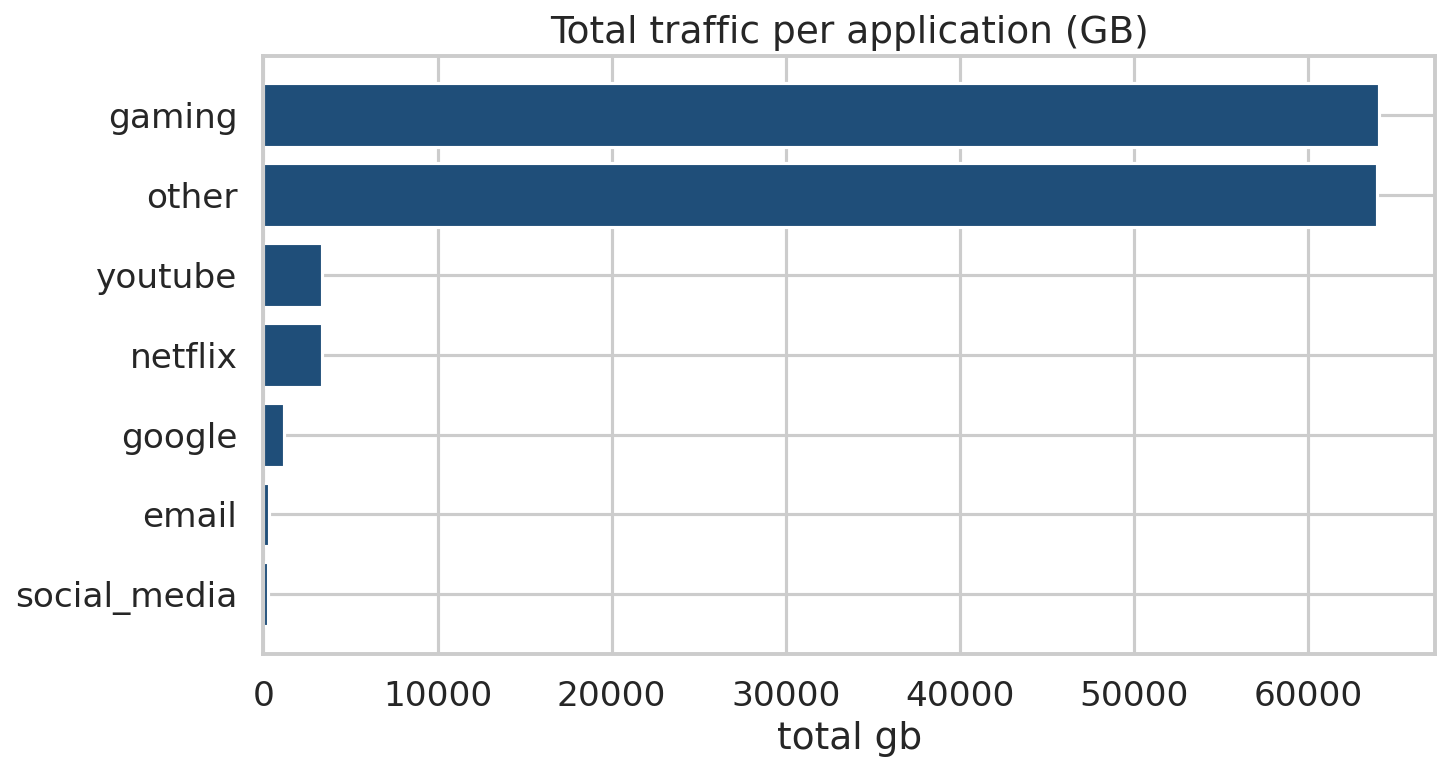

In [16]:
for app, table in engagement.top_users_per_app(users, 10).items():
    print('Top 10 users:', app); display(table)
display(engagement.top_apps(users, 3))
app_totals = pd.Series({a: users[f'{a}_bytes'].sum() / 1e9 for a in APPS}).sort_values(ascending=False)
show(viz.barh(app_totals.rename_axis('application').reset_index(name='total_gb'), 'application', 'total_gb',
                       'Total traffic per application (GB)', FIG / 'apps.png'))

## 16. Elbow method

optimal k (elbow): 3


,k,inertia,silhouette
0,1,862.80,NaN
1,2,431.76,0.61
2,3,292.95,0.52
3,4,245.38,0.33
4,5,208.62,0.34
5,6,180.53,0.35
6,7,156.36,0.35
7,8,138.35,0.36
8,9,126.54,0.37
9,10,115.37,0.36


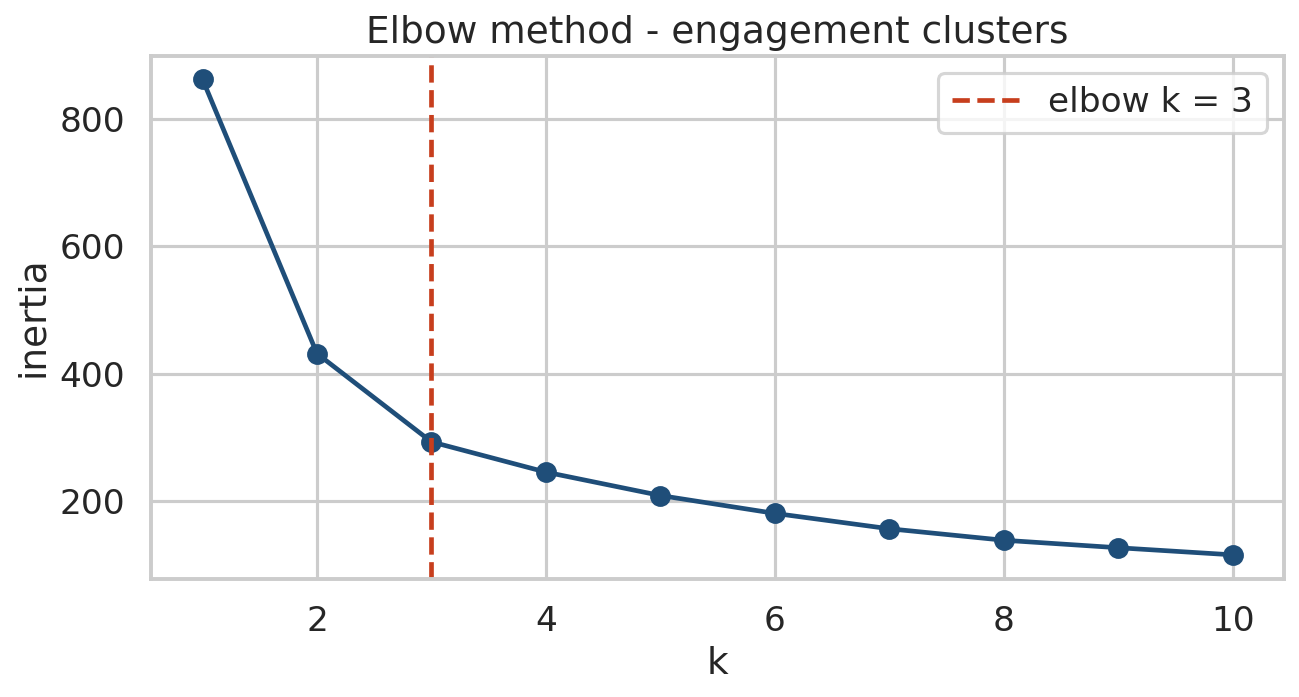

In [17]:
elbow = engagement.elbow(eng_scaled)
k_opt = engagement.optimal_k(elbow)
print('optimal k (elbow):', k_opt)
display(elbow)
show(viz.elbow_plot(elbow, k_opt, FIG / 'elbow.png'))

**Interpretation.** Inertia drops steeply up to k=3 and then flattens, so k=3 is a reasonable choice. The silhouette score is actually higher at k=2, so the three groups are a practical simplification rather than sharply separated segments.

# Task 3 - Experience analytics
## 17. Per-customer experience (Task 3.1)

In [18]:
exp_clean, exp_report = cleaning.treat_numeric(raw, EXPERIENCE_RAW)
display(exp_report.round(2))
exp_users = experience.experience_per_user(exp_clean)
print('users:', len(exp_users), '| handset filled with the most common model:', int(exp_users['handset_imputed'].sum()))
exp_users.head()

,column,pct_missing,pct_outlier,replacement_mean
0,rtt_dl_ms,18.55,9.37,47.25
1,rtt_ul_ms,18.54,7.50,7.89
2,tp_dl_kbps,0.00,8.82,"7,425.82"
3,tp_ul_kbps,0.00,14.35,366.37
4,tcp_dl_retrans_bytes,58.76,5.97,"1,311,050.97"
5,tcp_ul_retrans_bytes,64.43,4.94,"33,719.82"


users: 106856 | handset filled with the most common model: 6669


,msisdn,avg_tcp_retrans,avg_rtt_ms,avg_throughput_kbps,handset_type,handset_imputed
0,33601001722,"1,344,770.79",46.00,76.00,Huawei P20 Lite Huawei Nova 3E,False
1,33601001754,"1,344,770.79",31.00,99.00,Apple iPhone 7 (A1778),False
2,33601002511,"1,344,770.79",55.14,97.00,Huawei B528S-23A,True
3,33601007832,"34,785.82",84.00,248.00,Apple iPhone 5S (A1457),False
4,33601008617,"5,357,801.40",59.50,"20,400.69",Apple iPhone Se (A1723),False


## 18. Top, bottom and most frequent values (Task 3.2)
These use the original values, not the mean-filled ones. Otherwise the most frequent value would simply be the mean that was used to fill the gaps.

In [19]:
for name, (dl, ul) in {'TCP retransmission (bytes)': ('tcp_dl_retrans_bytes', 'tcp_ul_retrans_bytes'),
                       'RTT (ms)': ('rtt_dl_ms', 'rtt_ul_ms'),
                       'Throughput (kbps)': ('tp_dl_kbps', 'tp_ul_kbps')}.items():
    parts = experience.top_bottom_frequent(raw_session_metric(raw, dl, ul), 10)
    print('=====', name)
    for kind, table in parts.items():
        print(kind); display(table)

===== TCP retransmission (bytes)
top


,value
0,"4,344,115,651.00"
1,"4,301,477,439.00"
2,"4,294,431,965.00"
3,"4,291,464,950.00"
4,"4,288,120,860.00"
5,"4,275,491,713.00"
6,"4,268,647,350.00"
7,"4,261,616,039.00"
8,"4,260,174,145.00"
9,"4,254,659,643.00"


bottom


,value
0,2.00
1,2.00
2,3.00
3,3.00
4,3.00
5,3.00
6,3.00
7,4.00
8,4.00
9,4.00


most_frequent


...

,value
0,"382,262.00"
1,"313,244.00"
2,"304,299.00"
3,"300,546.00"
4,"283,931.00"
5,"281,144.00"
6,"277,152.00"
7,"276,205.00"
8,"274,052.00"
9,"269,888.00"


bottom


,value
0,0.00
1,0.00
2,0.00
3,0.00
4,0.00
5,0.00
6,0.00
7,0.00
8,0.00
9,0.00


most_frequent


,value,count
0,63.00,3886
1,15.00,3741
2,97.00,1945
3,90.00,1885
4,98.00,1801
5,96.00,1671
6,99.00,1571
7,89.00,1557
8,91.00,1520
9,93.00,1491


## 19. Throughput and TCP retransmission by handset (Task 3.3)

,handset_type,users,avg_throughput_kbps,median_throughput_kbps,avg_tcp_retrans,avg_rtt_ms
0,Huawei B528S-23A,10615,"21,195.63","20,751.16","2,061,494.93",81.51
1,Apple iPhone 6S (A1688),6759,"3,402.05",107.00,"1,283,030.16",45.08
2,Apple iPhone 6 (A1586),6260,"4,489.21",116.00,"1,277,698.73",46.86
3,Apple iPhone 7 (A1778),4699,"4,711.15",117.00,"1,292,795.03",49.28
4,Apple iPhone Se (A1723),3754,"3,556.68",108.00,"1,268,013.21",44.72
5,Apple iPhone 8 (A1905),3543,"3,856.29",115.75,"1,281,297.31",46.36
6,Samsung Galaxy S8 (Sm-G950F),3245,"6,874.08",136.00,"1,203,314.49",56.23
7,Apple iPhone Xr (A2105),3072,"3,911.60",112.00,"1,341,184.68",46.66
8,Samsung Galaxy J5 (Sm-J530),2748,"2,348.77",78.00,"1,253,049.06",51.26
9,Samsung Galaxy A5 Sm-A520F,2708,"4,679.23",116.00,"1,184,123.53",54.42


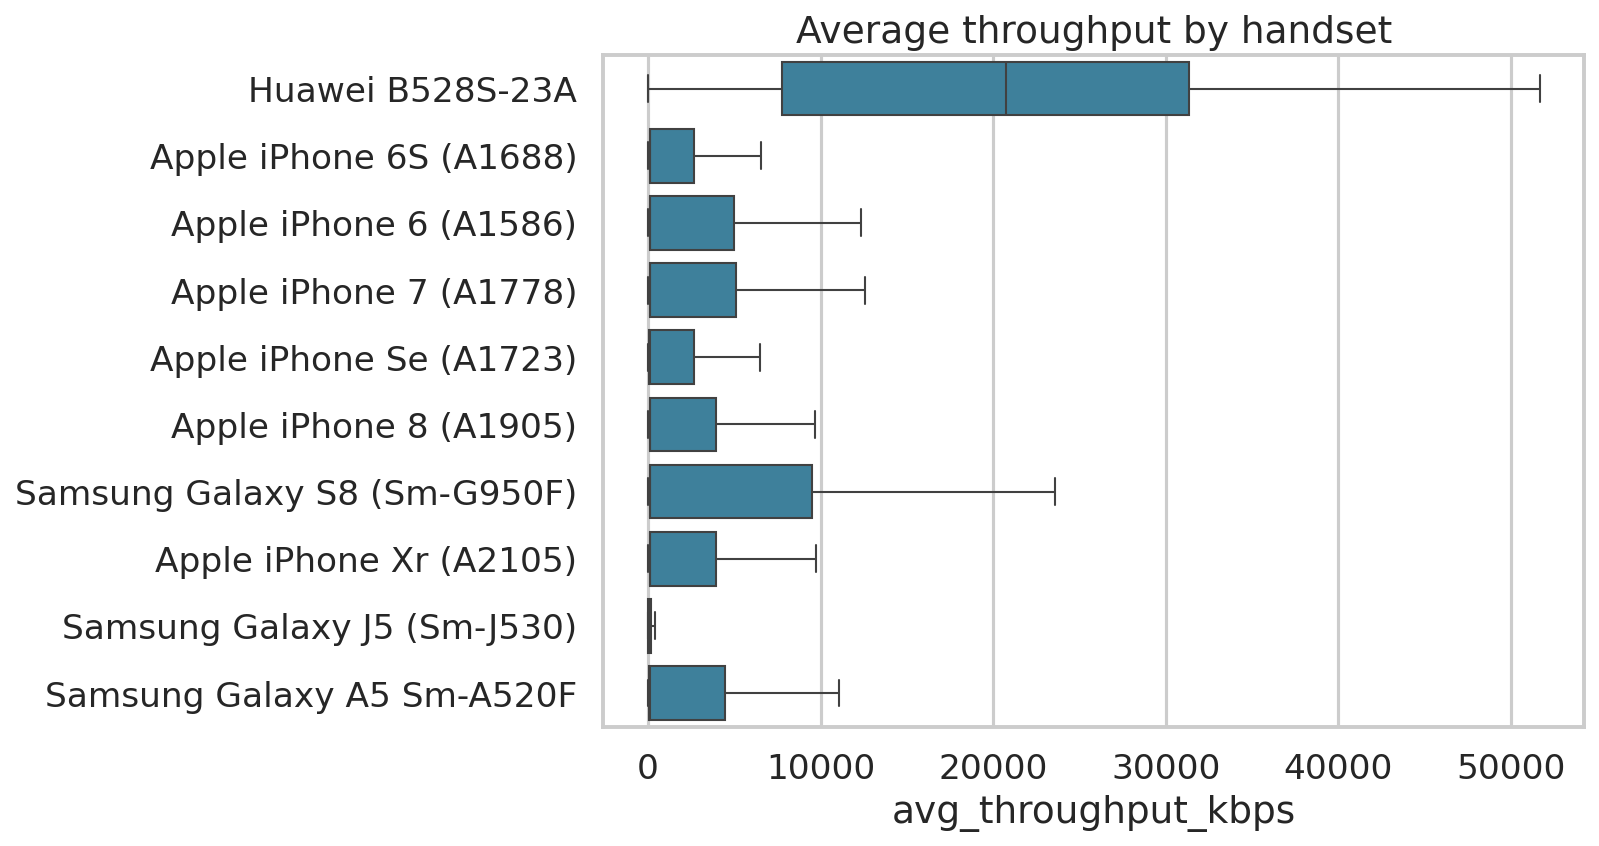

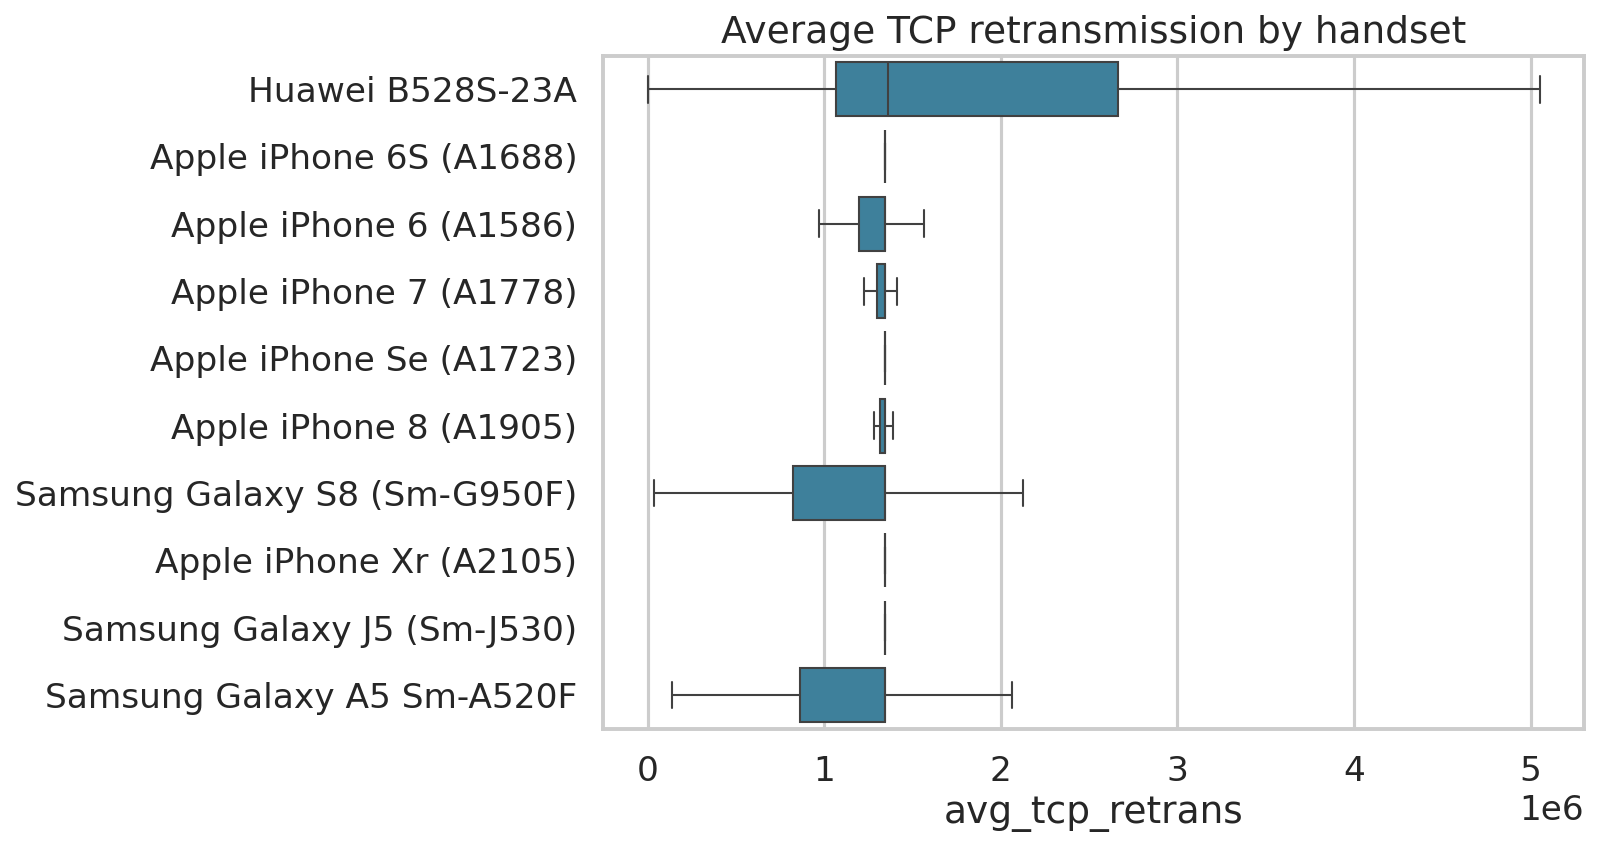

In [20]:
handsets = experience.per_handset(exp_users, min_users=100)
display(handsets.head(15))
top_names = handsets.head(10)['handset_type'].tolist()
known = exp_users[~exp_users['handset_imputed']]
show(viz.box_by_handset(known, top_names, 'avg_throughput_kbps', 'Average throughput by handset', FIG / 'tp_handset.png'))
show(viz.box_by_handset(known, top_names, 'avg_tcp_retrans', 'Average TCP retransmission by handset', FIG / 'tcp_handset.png'))

**Interpretation.** Router and hotspot devices (Huawei B528S-23A, E5xxx) average far higher throughput than phones, and they also show the highest TCP retransmission volume, because retransmitted bytes grow with the amount of data sent. Phone throughput is very skewed: medians are around 0.1 Mbps while means are several Mbps, so a minority of fast sessions lifts the averages.

## 20. K-means (k=3) experience segments (Task 3.4)

,cluster,users,avg_tcp_retrans,avg_rtt_ms,avg_throughput_kbps,description,is_worst
0,0,74127,"1,210,007.94",47.02,"1,039.12",WORST experience cluster - lowest TCP retransm...,True
1,1,11220,"1,788,185.98",72.55,"34,271.54","highest TCP retransmission, highest RTT, highe...",False
2,2,21509,"1,430,448.73",67.95,"13,160.07","middle TCP retransmission, middle RTT, middle ...",False


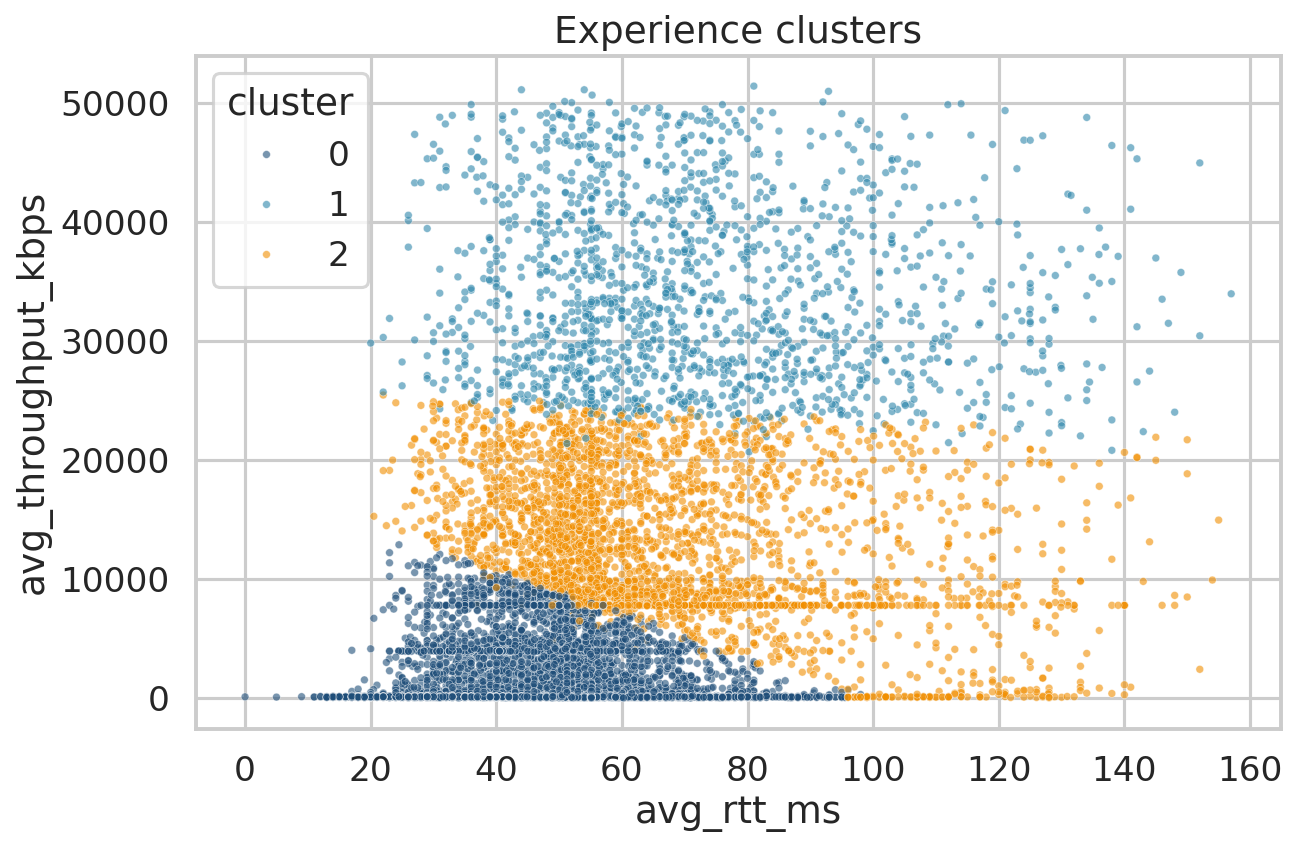

In [21]:
exp_labels, exp_model, exp_scaler, exp_scaled = experience.cluster_experience(exp_users, 3)
worst = experience.worst_experience_cluster(exp_model)
exp_clusters = experience.describe_clusters(exp_users, exp_labels, worst)
display(exp_clusters)
show(viz.scatter_clusters(exp_users.assign(cluster=exp_labels), 'avg_rtt_ms', 'avg_throughput_kbps', 'cluster',
                                   'Experience clusters', FIG / 'exp_clusters.png'))

**Cluster descriptions**
- **Low-throughput cluster (about 69% of users):** about 1 Mbps, but also the lowest RTT and TCP retransmission. This is labelled "worst experience" because of its low throughput. It may reflect light or background use as much as a weak network, and this data cannot separate the two.
- **Middle cluster (about 20%):** about 13 Mbps with moderate RTT and retransmission.
- **High-throughput cluster (about 10%):** about 34 Mbps, with the highest RTT and retransmission volume. These are the heavy users, mostly on router-type devices.

# Task 4 - Satisfaction
## 21. Engagement, experience and satisfaction scores (Tasks 4.1-4.2)
Each score is the Euclidean distance to a reference cluster centre in min-max normalised space. Satisfaction is the average of the two scores.

In [22]:
scores = satisfaction.build_score_table(eng, eng_scaled, eng_model, least, exp_users, exp_scaled, exp_model, worst)
print(len(scores), 'users | score spread (std):', scores[['engagement_score', 'experience_score']].std().round(2).to_dict())
satisfaction.top_satisfied(scores, 10)

106856 users | score spread (std): {'engagement_score': 0.07, 'experience_score': 0.22}


,msisdn,engagement_score,experience_score,satisfaction_score
0,33675877202,1.46,0.30,0.88
1,33614892860,1.58,0.18,0.88
2,33659725664,1.54,0.18,0.86
3,33626320676,1.59,0.12,0.86
4,33625779332,1.54,0.15,0.85
5,33664712899,1.19,0.43,0.81
6,33760536639,1.48,0.14,0.81
7,33659359429,1.14,0.44,0.79
8,33760413819,1.17,0.37,0.77
9,33604515716,1.04,0.43,0.74


**Note.** The experience score varies about three times more than the engagement score, so satisfaction is driven mostly by experience. The top-10 satisfied users score high mainly through engagement.

## 22. Regression model (Task 4.3)

,r2,rmse,mae
linear,0.92,0.03,0.03
gbr,1.00,0.01,0.00


,importance
avg_throughput_kbps,0.77
avg_rtt_ms,0.09
avg_tcp_retrans,0.06
sessions_frequency,0.04
total_traffic_bytes,0.02
duration_ms,0.02


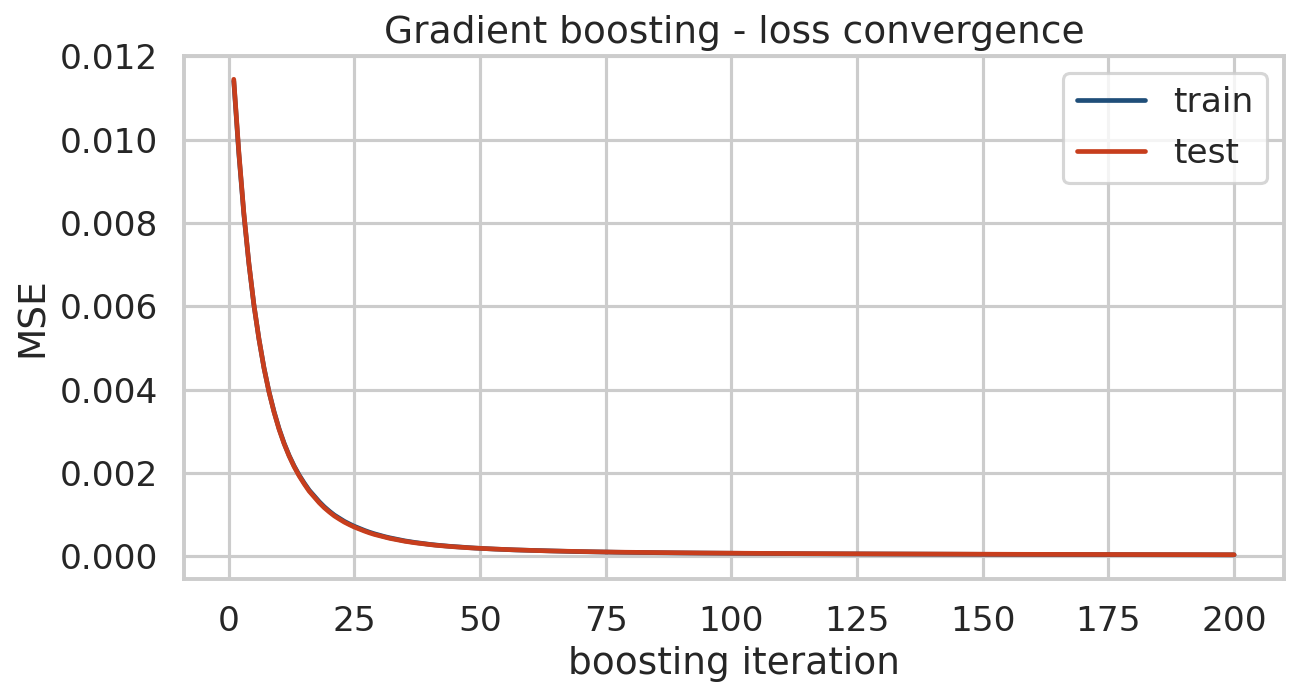

In [23]:
fit = satisfaction.train_regressors(scores)
display(pd.DataFrame(fit['metrics']).T)
display(fit['feature_importance'].to_frame('importance'))
show(viz.loss_curve(fit['loss_curve'], FIG / 'loss.png'))

**Interpretation.** Gradient boosting reaches R2 of about 0.997 and linear regression about 0.92. This is high because the target is calculated from the same inputs, so it shows the formula can be recovered, not that satisfaction is predictable from independent data.

## 23. K-means (k=2) on the scores and per-cluster averages (Tasks 4.4-4.5)

,satisfaction_cluster,users,avg_engagement_score,avg_experience_score,avg_satisfaction_score
0,0,86797,0.06,0.12,0.09
1,1,20059,0.07,0.61,0.34


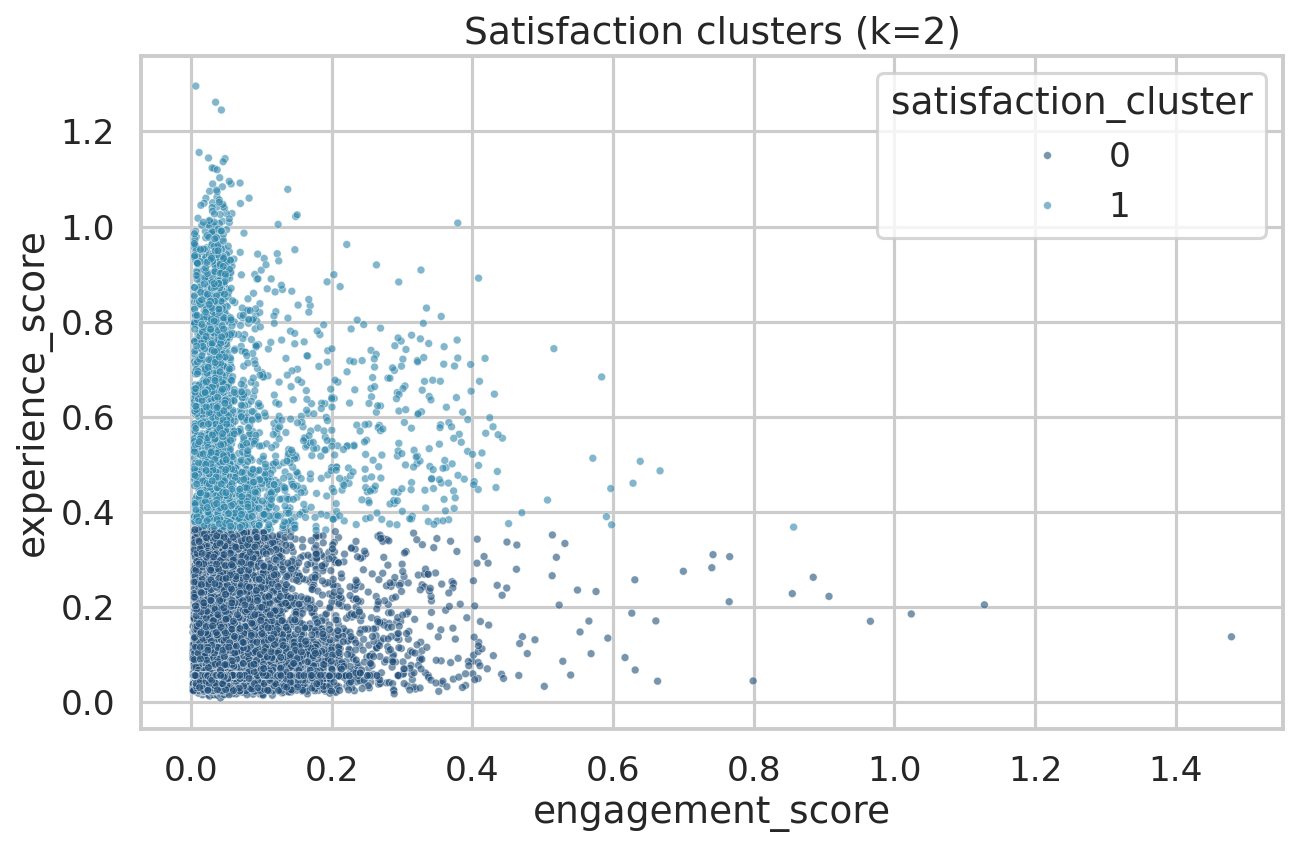

In [24]:
scored, sat_summary, sat_model = satisfaction.cluster_scores(scores, 2)
display(sat_summary)
show(viz.scatter_clusters(scored, 'engagement_score', 'experience_score', 'satisfaction_cluster',
                                   'Satisfaction clusters (k=2)', FIG / 'sat_clusters.png'))

**Interpretation.** The two clusters separate mainly on experience score: about 81% of users have low satisfaction (average about 0.09) and about 19% have higher satisfaction (about 0.34).

# Task 4.6 and 4.7 - MySQL export and model tracking
**MySQL:** MySQL must be installed and running. The cell below creates the database `telecom` and the table `user_satisfaction` for you; it asks for your password so it is never saved in the file.

In [25]:
EXPORT_TO_MYSQL = False   # change to True, run this cell, and type your MySQL password when asked
if EXPORT_TO_MYSQL:
    import getpass
    server, url = db.build_urls('root', getpass.getpass('MySQL root password: '))
    db.ensure_database(server)
    print(db.export_scores(scored, url), 'rows exported')
    display(db.preview(url))   # screenshot this for the report
else:
    print('Set EXPORT_TO_MYSQL = True above to export the table.')

Set EXPORT_TO_MYSQL = True above to export the table.


**Model tracking** (MLflow runs, feature store and CSV export) is done by the pipeline. Set the flag below to `True` to run it (about 3 minutes), or run `telco-pipeline` from the terminal.

In [26]:
RUN_FULL_PIPELINE = False
if RUN_FULL_PIPELINE:
    from telco_analytics import pipeline
    print(pipeline.run(str(RAW), 'artifacts'))

# Conclusions
- **Growth case (positive on network evidence):** most users have low throughput and usage is concentrated in a small heavy-user group, so network quality and plans aimed at heavy and router users have room to raise usage.
- **Router and hotspot customers** use more data and get the fastest service, a strong segment for fixed-wireless offers.
- **Decision:** do not buy on this analysis alone. The data has no revenue, churn or growth figures, so continue due diligence and buy only if the financials support the price.
- **Limitations:** one month of data; most users have a single session; application volumes exceed session totals; TCP retransmission is missing in about 57% of sessions and RTT in about 19%; mean replacement hides that; the regression is circular.